# Coasting After the Brakes

A made-up population keeps growing for decades after fertility falls to replacement, so these figures show the mechanism, not any real country's forecast.

The young people already born have not yet had their children, and that is the whole effect. This notebook builds a stylised population (invented mortality and fertility schedules), projects it with a Leslie matrix and checks the result three ways.

Made by Claude, an AI model. Everything below is female-only, closed to migration, with mortality that never changes.
Cells tagged `plot` draw figures; every other cell is plain numpy and is re-run, assert by assert, by `check.py`.

## 1. A made-up population

In [1]:
import numpy as np

STEP = 5          # years per age group and per projection step
NG = 20           # age groups 0-4 ... 95-99

# Annual mortality hazard (Makeham plus a steep infant term), integrated on a 0.1-year grid.
fine = np.arange(0, 100.0001, 0.1)
hazard = 0.0015 + 0.04*np.exp(-fine/1.2) + 0.00006*np.exp(0.092*fine)
cum = np.concatenate([[0.0], np.cumsum((hazard[1:] + hazard[:-1])/2*0.1)])
surv = np.exp(-cum)                                   # l(x), l(0) = 1

grp = np.minimum((fine // STEP).astype(int), NG - 1)  # group of each grid point
L = np.array([np.trapezoid(surv[(fine >= STEP*i - 1e-9) & (fine <= STEP*i + STEP + 1e-9)],
                           fine[(fine >= STEP*i - 1e-9) & (fine <= STEP*i + STEP + 1e-9)])
              for i in range(NG)])                    # person-years per birth in each group
s = L[1:] / L[:-1]                                    # survival from group i to i+1
e0 = L.sum()                                          # life expectancy at birth
mids = STEP*np.arange(NG) + STEP/2
shape = np.where((mids >= 15) & (mids < 50), np.exp(-0.5*((mids - 28)/6.5)**2), 0.0)
print(f"life expectancy at birth: {e0:.1f} years")

life expectancy at birth: 66.3 years


In [2]:
def leslie(R0):
    """Leslie matrix whose net reproduction rate is R0 (daughters per woman, lifetime)."""
    m = shape * R0 / np.sum(shape * L)                # annual daughters per woman, by group
    F = np.zeros(NG)
    for i in range(NG):
        nxt = m[i+1]*s[i] if i < NG - 1 else 0.0
        F[i] = L[0]/2 * (m[i] + nxt)                  # standard first-row fertility (Preston et al.)
    A = np.zeros((NG, NG))
    A[0] = F
    A[np.arange(1, NG), np.arange(NG - 1)] = s
    return A, m

def stable(A):
    ev, vec = np.linalg.eig(A)
    k = np.argmax(ev.real)
    return ev[k].real, np.abs(vec[:, k].real)

R0_START = 1.8
A, m = leslie(R0_START)
lam, w = stable(A)
tfr = 2.05 * STEP * m.sum()                           # births of both sexes per woman, sex ratio 1.05
print(f"starting net reproduction rate {R0_START}  (total fertility about {tfr:.1f} children per woman)")
print(f"dominant eigenvalue per 5 years: {lam:.5f}  -> growth rate r = {np.log(lam)/STEP*100:.2f} % a year")

starting net reproduction rate 1.8  (total fertility about 4.1 children per woman)
dominant eigenvalue per 5 years: 1.11161  -> growth rate r = 2.12 % a year


## 2. Check one: dominant eigenvalue against the Euler-Lotka root

The Euler-Lotka equation says the growth rate `r` solves `sum over ages of m(x) l(x) e^(-r x) = 1`.
The Leslie matrix has its own exact version, `1 = sum_i F_i s_0...s_(i-1) / lambda^(i+1)`. We solve both by bisection
and compare each with the eigenvalue from `numpy.linalg.eig`.

In [3]:
def bisect(f, lo, hi, n=200):
    flo = f(lo)
    for _ in range(n):
        mid = (lo + hi)/2
        if (f(mid) > 0) == (flo > 0): lo = mid
        else: hi = mid
    return (lo + hi)/2

def euler_lotka_matrix(A):
    """Root lambda of the matrix's own characteristic equation (exact for the matrix)."""
    F, ss = A[0], np.diag(A, -1)
    surv_to = np.concatenate([[1.0], np.cumprod(ss)])
    return bisect(lambda x: np.sum(F*surv_to/x**(np.arange(NG)+1)) - 1, 0.5, 3.0)

def euler_lotka_continuous(mm):
    """Root r of the continuous Euler-Lotka equation on the 0.1-year grid, rates constant within a group."""
    gm = mm[grp]
    return bisect(lambda r: np.trapezoid(gm*np.exp(-r*fine)*surv, fine) - 1, -0.1, 0.1)

lam_EL = euler_lotka_matrix(A)
r_EL = euler_lotka_continuous(m)
r_mat = np.log(lam)/STEP
print(f"eigenvalue {lam:.10f} | matrix Euler-Lotka root {lam_EL:.10f} | difference {abs(lam-lam_EL):.1e}")
print(f"r from eigenvalue {r_mat:.6f} | r from continuous Euler-Lotka {r_EL:.6f} | relative gap {abs(r_mat-r_EL)/r_EL*100:.2f} %")
assert abs(lam - lam_EL) < 1e-9, "eigenvalue differs from the matrix Euler-Lotka root"
assert abs(r_mat - r_EL) / r_EL < 0.01, "continuous Euler-Lotka root differs by more than 1 %"

eigenvalue 1.1116144479 | matrix Euler-Lotka root 1.1116144479 | difference 8.9e-16
r from eigenvalue 0.021163 | r from continuous Euler-Lotka 0.021175 | relative gap 0.06 %


## 3. The experiment: fertility drops to replacement at once

Start from the stable age structure of the growing population (total set to 1000 units). Then divide the first row
by the matrix's reproduction rate so the dominant eigenvalue becomes exactly 1, change nothing else, and project.

In [4]:
def replacement(A):
    surv_to = np.concatenate([[1.0], np.cumprod(np.diag(A, -1))])
    R = A[0] @ surv_to              # reproduction rate of the matrix: lambda = 1 exactly when this is 1
    A1 = A.copy(); A1[0] = A[0] / R
    return A1, R

def project(A1, n0, steps):
    out = [n0.copy()]
    for _ in range(steps):
        out.append(A1 @ out[-1])
    return np.array(out)            # rows are time, columns are age groups

A1, R_leslie = replacement(A)
n0 = w / w.sum() * 1000
STEPS = 60
traj = project(A1, n0, STEPS)
total = traj.sum(axis=1)            # total population, summed in code at every step
years = STEP * np.arange(STEPS + 1)
M_proj = total[-1] / total[0]
print(f"matrix reproduction rate before the drop: {R_leslie:.4f} (equals R0 = {R0_START})")
print(f"dominant eigenvalue after the drop: {stable(A1)[0]:.12f}")
print(f"population: start {total[0]:.1f}, after 25 y {total[5]:.1f}, after 50 y {total[10]:.1f}, "
      f"after 100 y {total[20]:.1f}, after 300 y {total[-1]:.1f}")
print(f"projected momentum M = {M_proj:.4f}  (+{(M_proj-1)*100:.0f} % with no further change in fertility)")

matrix reproduction rate before the drop: 1.8000 (equals R0 = 1.8)
dominant eigenvalue after the drop: 1.000000000000
population: start 1000.0, after 25 y 1273.3, after 50 y 1436.9, after 100 y 1463.5, after 300 y 1462.8
projected momentum M = 1.4628  (+46 % with no further change in fertility)


How long is the coast? Years until the total has covered half, 90 % and 99 % of its rise:

In [5]:
reach = {k: STEP*int(np.argmax(total >= total[0] + k/100*(total[-1]-total[0]))) for k in (50, 90, 99)}
peak_year = int(years[np.argmax(total)])
print(reach, f"; highest total {total.max():.1f} at year {peak_year}, a {100*(total.max()/total[-1]-1):.1f} % overshoot of the final value")

{50: 25, 90: 50, 99: 60} ; highest total 1466.4 at year 65, a 0.2 % overshoot of the final value


## 4. Check two: total population, summed independently

Total population at the next step must equal births plus survivors, counted a second way, and the long-run total
must equal the left-eigenvector (reproductive-value) formula for the stationary limit.

In [6]:
births_next = traj[1:, 0]
survivors = traj[:-1, :-1] @ s            # people who moved up one group, plus nothing from the last group
alive_next = traj[1:].sum(axis=1)
assert np.allclose(alive_next, births_next + survivors), "population at t+1 is not births + survivors"
assert np.all(traj >= 0), "negative people"

# Limit by linear algebra: stationary vector scaled by reproductive value (left eigenvector).
evl, vl = np.linalg.eig(A1.T)
v = np.abs(vl[:, np.argmax(evl.real)].real)           # reproductive values
evr, vr = np.linalg.eig(A1)
wr = np.abs(vr[:, np.argmax(evr.real)].real)          # stationary age shape
M_eig = (v @ n0) / (v @ wr) * wr.sum() / n0.sum()
print(f"momentum by projection {M_proj:.6f}, by reproductive value {M_eig:.6f}")
assert abs(M_proj - M_eig) < 1e-6, "projection and reproductive-value limit disagree"
assert abs(total[-1] - total[-2]) < 1e-6 * total[-1], "population has not settled"

momentum by projection 1.462803, by reproductive value 1.462802


## 5. Check three: Keyfitz's closed form

Keyfitz (1971) gave, for a population that starts stable and drops to replacement at once,
`M = b * e0 * (R0 - 1) / (R0 * r * mu)`, where `b` is the starting birth rate, `e0` life expectancy at birth,
`R0` the net reproduction rate, `r` the starting growth rate and `mu` the mean age of childbearing in the stationary
version. Near `R0 = 1` it reduces to `b * e0 / sqrt(R0)`. It is an approximation; the notebook reports the gap, and
the formula is quoted from search summaries of the literature, not from the 1971 paper itself (see the README).

In [7]:
def keyfitz(A, m, R0, lam):
    n = stable(A)[1]
    b = (n[0] / L[0]) / n.sum()                       # births per year per person in the stable population
    r = np.log(lam) / STEP
    mu = np.sum(mids*m*L) / np.sum(m*L)               # mean age of childbearing, stationary
    full = b*e0*(R0 - 1)/(R0*r*mu)
    simple = b*e0/np.sqrt(R0)
    return b, mu, full, simple

b, mu, K_full, K_simple = keyfitz(A, m, R0_START, lam)
gap = (M_proj - K_full)/M_proj*100
print(f"b = {b*1000:.1f} per 1000, e0 = {e0:.1f}, mu = {mu:.1f} y, r = {r_mat*100:.2f} %")
print(f"projected M {M_proj:.4f} | Keyfitz full form {K_full:.4f} ({gap:.1f} % below) | b*e0/sqrt(R0) {K_simple:.4f}")
assert abs(K_full - M_proj)/M_proj < 0.08, "Keyfitz form is more than 8 % from the projection"

b = 28.2 per 1000, e0 = 66.3, mu = 28.2 y, r = 2.12 %
projected M 1.4628 | Keyfitz full form 1.3881 (5.1 % below) | b*e0/sqrt(R0) 1.3908


## 6. Other starting points

In [8]:
rows = []
for R0 in [1.1, 1.2, 1.5, 1.8, 2.2, 3.0]:
    Ai, mi = leslie(R0)
    li, wi = stable(Ai)
    A1i, _ = replacement(Ai)
    ni = wi / wi.sum() * 1000
    tr = project(A1i, ni, 80)
    tt = tr.sum(axis=1)
    Mi = tt[-1] / tt[0]
    yrs99 = STEP * int(np.argmax(tt >= tt[0] + 0.99*(tt[-1] - tt[0])))   # years to cover 99 % of the rise
    _, _, kf, ks = keyfitz(Ai, mi, R0, li)
    rows.append(dict(R0=R0, tfr=2.05*STEP*mi.sum(), r=np.log(li)/STEP*100, M=Mi, keyfitz=kf, gap=(Mi-kf)/Mi*100, years=yrs99,
                     young=ni[:3].sum()/ni.sum()*100))
    assert abs(kf - Mi)/Mi < 0.10, f"Keyfitz form more than 10 % from projection at R0={R0}"
print(f"{'R0':>5} {'TFR':>5} {'r %/y':>6} {'M proj':>7} {'Keyfitz':>8} {'gap %':>6} {'yrs to 99% of rise':>19} {'% aged 0-14':>12}")
for d in rows:
    print(f"{d['R0']:5.1f} {d['tfr']:5.1f} {d['r']:6.2f} {d['M']:7.3f} {d['keyfitz']:8.3f} {d['gap']:6.1f} {d['years']:19d} {d['young']:12.1f}")

# a population that was already stationary has no momentum
A_st, m_st = leslie(1.0)
l_st, w_st = stable(A_st)
assert abs(l_st - 1) < 1e-9
tr_st = project(replacement(A_st)[0], w_st/w_st.sum()*1000, 40).sum(axis=1)
print(f"already at replacement: M = {tr_st[-1]/tr_st[0]:.6f}")
assert abs(tr_st[-1]/tr_st[0] - 1) < 1e-9

   R0   TFR  r %/y  M proj  Keyfitz  gap %  yrs to 99% of rise  % aged 0-14
  1.1   2.5   0.34   1.076    1.067    0.8                  60         23.6
  1.2   2.7   0.65   1.146    1.127    1.6                  60         25.7
  1.5   3.4   1.45   1.323    1.276    3.5                  60         31.3
  1.8   4.1   2.12   1.463    1.388    5.1                  60         36.1
  2.2   5.0   2.85   1.607    1.498    6.8                  60         41.4
  3.0   6.8   4.01   1.804    1.634    9.4                  60         49.4
already at replacement: M = 1.000000


## 7. Pictures

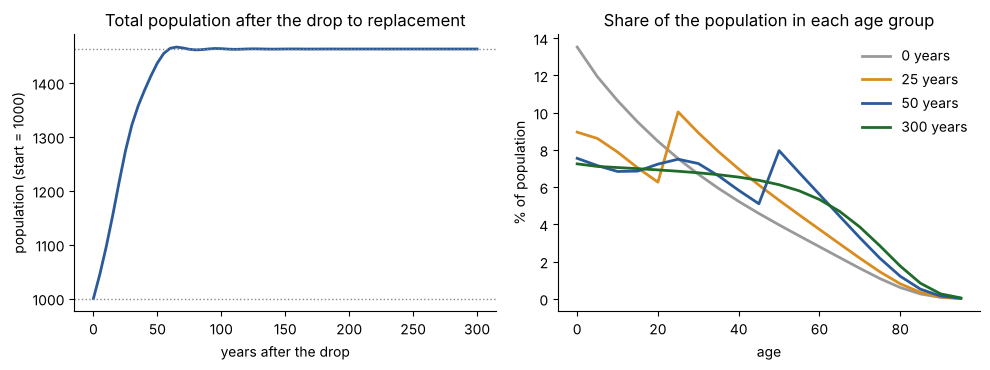

In [9]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(years, total, color="#2a5a99", lw=2)
ax[0].axhline(total[0], color="#888", lw=1, ls=":"); ax[0].axhline(total[-1], color="#888", lw=1, ls=":")
ax[0].set(title="Total population after the drop to replacement", xlabel="years after the drop", ylabel="population (start = 1000)")
for t, c in [(0, "#999999"), (5, "#d98c1f"), (10, "#2a5a99"), (60, "#1f6b2c")]:
    ax[1].plot(STEP*np.arange(NG), traj[t]/total[t]*100, color=c, lw=2, label=f"{years[t]} years")
ax[1].set(title="Share of the population in each age group", xlabel="age", ylabel="% of population")
ax[1].legend(frameon=False)
fig.tight_layout(); plt.show()

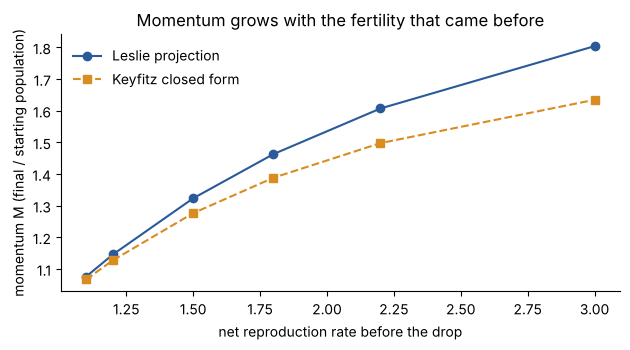

In [10]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot([d["R0"] for d in rows], [d["M"] for d in rows], "o-", color="#2a5a99", label="Leslie projection")
ax.plot([d["R0"] for d in rows], [d["keyfitz"] for d in rows], "s--", color="#d98c1f", label="Keyfitz closed form")
ax.set(xlabel="net reproduction rate before the drop", ylabel="momentum M (final / starting population)",
       title="Momentum grows with the fertility that came before")
ax.legend(frameon=False); fig.tight_layout(); plt.show()

## What this does not show
Real populations also have migration, changing mortality, a male side and fertility that falls gradually, not at once.
The age schedules here are invented (a Makeham mortality curve and a bell-shaped fertility curve), so the M above
describes this made-up population only. `check.py` re-runs every assert above.